<a href="https://colab.research.google.com/github/alokchoudharyguliya/Applied-Accelerated-AI/blob/main/Week5_TF_Acceleration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time
import os
import tempfile
import shutil

After 200 steps:
W=2.0000 (target:2.0)
b=2.0000 (target:1.0)
Final loss=0.00000


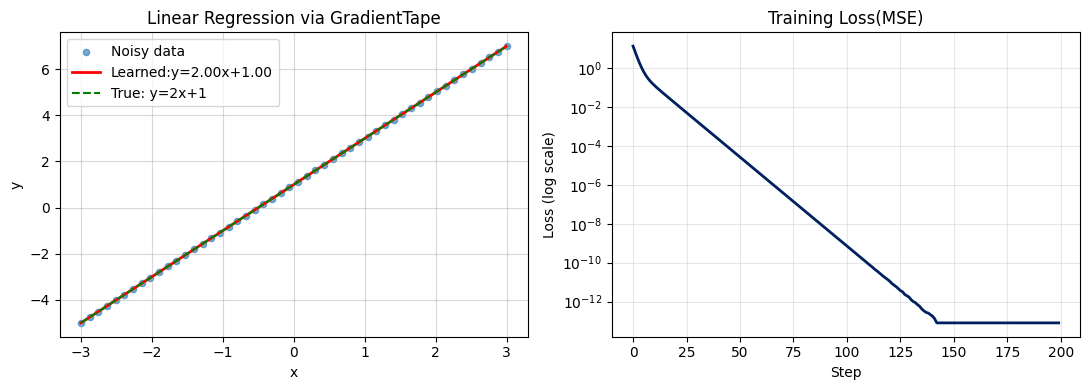

Figure saved.


In [11]:
np.random.seed(42)
x_train=tf.constant(np.linspace(-3,3,50),dtype=tf.float32)
y_train=tf.constant(2.0*x_train+1.0+np.random.randn(50)*0.,dtype=tf.float32)

W=tf.Variable(0.0,name="weight")
b=tf.Variable(0.0,name='bias')
optimizer=tf.optimizers.SGD(learning_rate=0.05)

losses=[]
for step in range(200):
  with tf.GradientTape() as tape:
    y_pred=W*x_train+b
    loss=tf.reduce_mean(tf.square(y_pred-y_train))
  grads=tape.gradient(loss,[W,b])
  optimizer.apply_gradients(zip(grads,[W,b]))
  losses.append(loss.numpy())
print("After 200 steps:")
print(f"W={W.numpy():.4f} (target:2.0)")
print(f"b={W.numpy():.4f} (target:1.0)")
print(f"Final loss={losses[-1]:.5f}")

# Plot
fig, (ax1, ax2)=plt.subplots(1,2,figsize=(11,4))
ax1.scatter(x_train.numpy(),y_train.numpy(),s=20,alpha=0.6, label="Noisy data")
x_line=np.linspace(-3,3,100)
ax1.plot(x_line, W.numpy()*x_line+b.numpy(), 'r-',lw=2,label=f'Learned:y={W.numpy():.2f}x+{b.numpy():.2f}')
ax1.plot(x_line,2*x_line+1,'g--',lw=1.5,label='True: y=2x+1')
ax1.legend();

ax1.set_title('Linear Regression via GradientTape')
ax1.set_xlabel('x');ax1.set_ylabel('y');ax1.grid(alpha=0.5)

ax2.semilogy(losses,color='#002060',lw=2)
ax2.set_title('Training Loss(MSE)');ax2.set_xlabel('Step');ax2.set_ylabel('Loss (log scale)')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("lec1_regression.png",dpi=100,bbox_inches='tight')
plt.show()
print("Figure saved.")

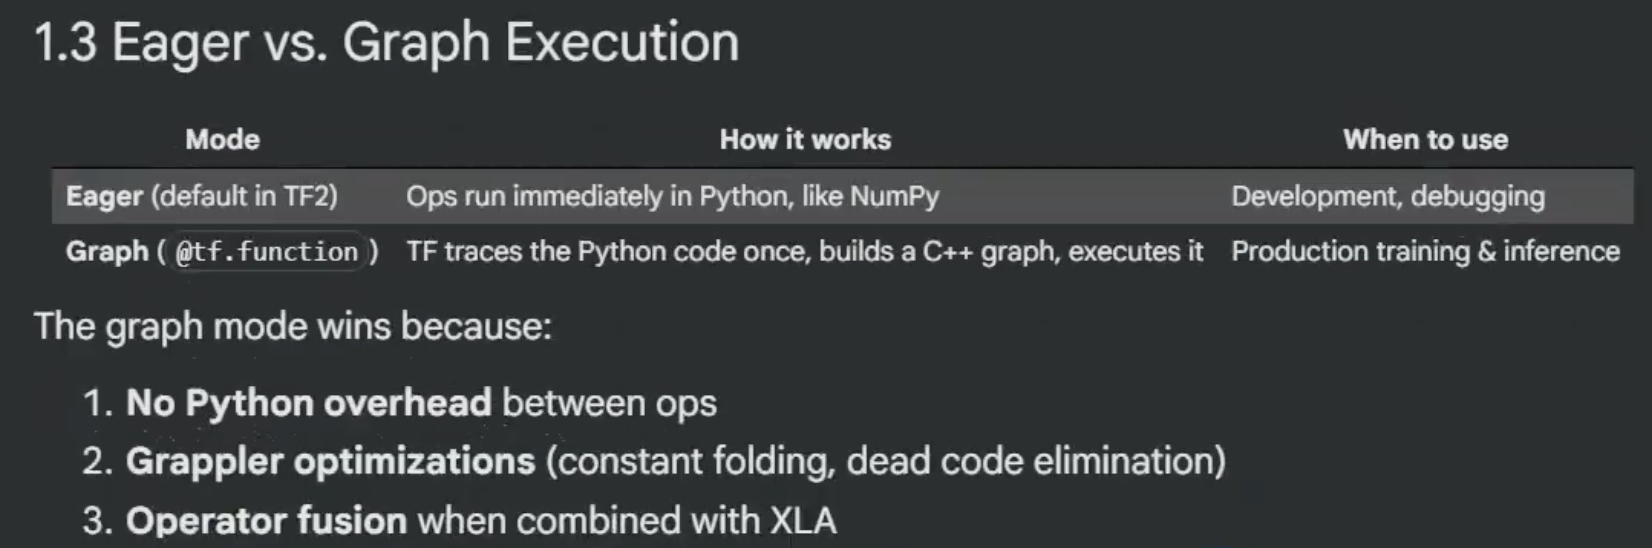

Eager execution:2.290 ms / call
Graph execution:0.944 ms / call
Speedup        :2.425 ms / call


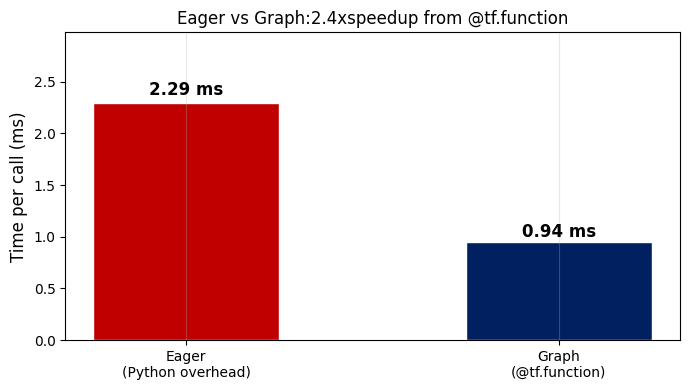

In [16]:
# ---- 1.5 Eager vs Graph Execution Benchmark ----
def heavy_computation(x):
  """
  A compute-heavy sequence of ops
  """
  for _ in range(10):
    x=tf.matmul(x,x)
    y=tf.nn.relu(x)
  return x

# Compiled(graph) version
heavy_graph=tf.function(heavy_computation)
data=tf.random.normal([32,32])

# Warm0up: triggers graph tracing on firsst call
_=heavy_graph(data)
N=20
# Time eager
t0=time.perf_counter()
for _ in range(N):
  _=heavy_computation(data)
eager_ms=(time.perf_counter()-t0)/N*1000

# Time graph
t0=time.perf_counter()
for _ in range(N):
  _=heavy_graph(data)
graph_ms=(time.perf_counter()-t0)/N*1000

speedup=eager_ms/graph_ms
print(f"Eager execution:{eager_ms:.3f} ms / call")
print(f"Graph execution:{graph_ms:.3f} ms / call")
print(f"Speedup        :{speedup:.3f} ms / call")

# Plot
fig,ax=plt.subplots(figsize=(7,4))
bars=ax.bar(['Eager\n(Python overhead)','Graph\n(@tf.function)'],
            [eager_ms,graph_ms],
            color=['#C00000','#002060'],width=0.5,edgecolor='white')
for bar, val in zip(bars,[eager_ms, graph_ms]):
  ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()*1.02,
          f'{val:.2f} ms',ha='center',va='bottom',fontweight='bold',fontsize=12)
ax.set_ylabel("Time per call (ms)", fontsize=12)
ax.set_title(f"Eager vs Graph:{speedup:.1f}xspeedup from @tf.function",fontsize=12)
ax.set_ylim(0,max(eager_ms,graph_ms)*1.3)
ax.grid(axis='x',alpha=0.3)
plt.tight_layout()
plt.savefig('lec1_eager_vs_graph.png',dpi=100, bbox_inches='tight')
plt.show()

In [17]:
# 1.6 ------ Inspecting the Computation Graph ------
@tf.function
def forward_pass(x,w,b):
  """
  A two layer forward pass
  """
  h=tf.nn.relu(tf.matmul(x,w)+b)
  out=tf.reduce_mean(h)
  return out
# Get the concrete function for a specific input signature
x_spec=tf.TensorSpec(shape=[None,4],dtype=tf.float32)
w_spec=tf.TensorSpec(shape=[4,8],dtype=tf.float32)
b_spec=tf.TensorSpec(shape=[8],dtype=tf.float32)
cf=forward_pass.get_concrete_function(x_spec,w_spec,b_spec)
graph=cf.graph
print(f"{'Operation type':30s} Node name")
print("-"*60)
for op in graph.get_operations():
  print(f" {op.type:28s} {op.name}")
print(f"\nTotal ops: {len(graph.get_operations())}")
print(f"Graph inputs: {[t.name for t in cf.inputs]}")
print(f"Graph outputs: {[t.name for t in cf.outputs]}")

Operation type                 Node name
------------------------------------------------------------
 Placeholder                  x
 Placeholder                  w
 Placeholder                  b
 MatMul                       MatMul
 AddV2                        add
 Relu                         Relu
 Const                        Const
 Mean                         Mean
 Identity                     Identity

Total ops: 9
Graph inputs: ['x:0', 'w:0', 'b:0']
Graph outputs: ['Identity:0']


Modern GPUs can process thousands of images per second. Without pipeline optimizations:

- GPU finishes batch N -> sits idle waiting for CPU to prepare N+1
- 40-70% of expensive GPU time is wasted on I/O wait

Key Idea: Overlap CPU preprocessing with GPU training using prefetching


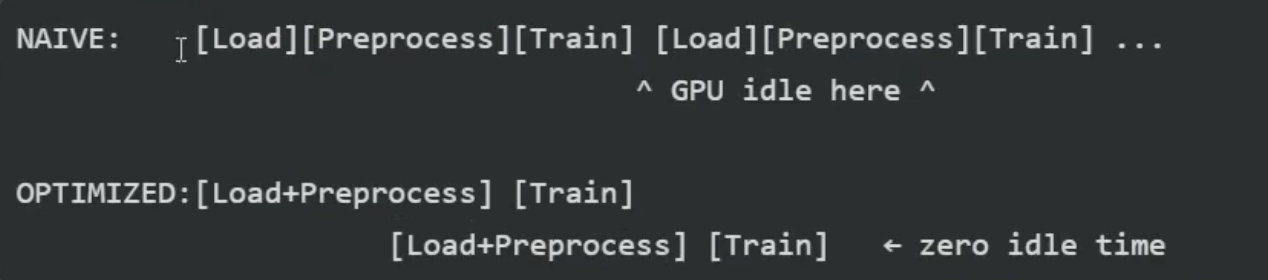

In [20]:
# ---- 2.1 Creating tf.data Datasets -----

# ---- Method 1: from in-memory NumPy arrays -----
images=np.random.randn(100,14,14,1).astype(np.float32)
labels=np.random.randint(0,10,100).astype(np.int32)

ds_numpy=tf.data.Dataset.from_tensor_slices((images, labels))
print(f"from tensor_slices -> {ds_numpy.element_spec}")

def data_generator():
  for i in range(30):
    yield np.random.randn(14,14,1).astype(np.float32), np.int32(i%10)

ds_gen=tf.data.Dataset.from_generator(
    data_generator,
    output_signature=(
        tf.TensorSpec(shape=(14,14,1),dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
)
print(f"from_generator         -> {ds_gen.element_spec}")

# ---- Method 3: range/ synthetic ----
ds_range=tf.data.Dataset.range(100)
print(f"Dataset.range(100)     -> {ds_range.element_spec}")

# --- Peek at elements ---
print("\nFirst 3 samples from ds_numpy:")
for img, lbl in ds_numpy.take(3):
  print(f"  image shape: {img.shape} label: {lbl.numpy()}")

from tensor_slices -> (TensorSpec(shape=(14, 14, 1), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))
from_generator         -> (TensorSpec(shape=(14, 14, 1), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))
Dataset.range(100)     -> TensorSpec(shape=(), dtype=tf.int64, name=None)

First 3 samples from ds_numpy:
  image shape: (14, 14, 1) label: 5
  image shape: (14, 14, 1) label: 7
  image shape: (14, 14, 1) label: 9


In [21]:
# ---- 2.2 Core Dataset Transformation ----
# --- .map() : element-wise transformation ---
@tf.function
def preprocess(image, label):
  """
  Normalize to [-1,1] and apply random noise augmentation
  """
  image=tf.cast(image,tf.float32)/127.5-1.0
  image=image+tf.random.normal(tf.shape(image),stddev=0.01)
  image=tf.clip_by_value(image,-1.0, 1.0)
  return image, label

# Build the optimized pipeline step by step
ds=(
    tf.data.Dataset.from_tensor_slices((images,labels))
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(buffer_size=200, reshuffle_each_iteration=True)
    .batch(16,drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Pipeline element spec:")
for spec in ds.element_spec:
  print(f"{spec}")
for img_b,lbl_b in ds.take(1):
  print(f"\nBatch -> images: {img_b.shape} label: {lbl_b.shape}")
  print(f"image value range: [{img_b.numpy().min():.3f},{img_b.numpy().max():.3f}]")


Pipeline element spec:
TensorSpec(shape=(16, 14, 14, 1), dtype=tf.float32, name=None)
TensorSpec(shape=(16,), dtype=tf.int32, name=None)

Batch -> images: (16, 14, 14, 1) label: (16,)
image value range: [-1.000,-0.954]


In [22]:
# ---- 2.3 .cache(): Eliminate Redundant Preprocessing ----
#
# without .cache(): map() runs on every epoch
# with .cache(): map() runs ONCE; results stored in RAM (or file)

N_ITEMS=200
ds_raw=tf.data.Dataset.range(N_ITEMS)

def preprocess_int(x):
  return tf.cast(x,tf.float32)*2.0

ds_no_cache=ds_raw.map(preprocess_int).batch(20)
ds_cached=ds_raw.map(preprocess_int).cache().batch(20)

def time_epochs(ds,n_epochs=4, name=''):
  times=[]
  for ep in range(n_epochs):
    t0=time.perf_counter()
    for _ in ds: pass
    times.append((time.perf_counter()-t0)*1000)
  print(f"{name:25s}:{[f"{t:.1f}ms" for t in times]}")
  return times

print("Epoch times over 4 epochs (cahce fills on epoch 1):")
t_no=time_epochs(ds_no_cache,name="Without .cache()")
t_c=time_epochs(ds_cached,name="With .cache()")

print(f"\n Epoch 2 speedup from .cache(): {t_no[1]/max(t_c[1],0.001):.1f}x")

Epoch times over 4 epochs (cahce fills on epoch 1):
Without .cache()         :['43.3ms', '21.8ms', '31.0ms', '70.8ms']
With .cache()            :['101.7ms', '10.9ms', '7.2ms', '22.2ms']

 Epoch 2 speedup from .cache(): 2.0x


In [27]:
# ---- 2.4 Parallel Processing: run_parallel_calls ----
N=400
x_data=np.random.randn(N,14,14,1).astype(np.float32)
y_data=np.random.randint(0,100,N).astype(np.int32)

@tf.function
def augment(img, lbl):
  img=img+tf.random.normal(tf.shape(img),stddev=0.05)
  img=tf.image.rot90(img,k=tf.random.uniform([],0,4,dtype=tf.int32))
  img=tf.clip_by_value(img,-3.0,3.0)
  return img, lbl

# Sequential map
ds_seq=(tf.data.Dataset.from_tensor_slices((x_data, y_data)).map(augment, num_parallel_calls=1).batch(32).prefetch(1))
ds_par=(tf.data.Dataset.from_tensor_slices((x_data, y_data)).map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(32).prefetch(tf.data.AUTOTUNE))

def time_pipeline(ds, reps=3):
  times=[]
  for _ in range(reps):
    t0=time.perf_counter()
    for _ in ds: pass
    times.append((time.perf_counter()-t0)*1000)

  return np.mean(times)
t_seq=time_pipeline(ds_seq)
t_par=time_pipeline(ds_par)
print(f"Sequential map(workers=1)   :{t_seq:.1f} ms")
print(f"Parallel map(AUTOTUNE)   :{t_seq:.1f} ms")
print(f"Parallelism speedup   :{t_seq/max(t_par,0.001):.2f}x")


Sequential map(workers=1)   :238.4 ms
Parallel map(AUTOTUNE)   :238.4 ms
Parallelism speedup   :1.21x


In [36]:
# ---- 2.5 TFRecord : The optimal disk storage format ----
#
# Why TFRecord ?
# - Sequential reads : saturates disk bandwidth
# - No per file overhead like JPEG/PNG directories
# - Native to TF -> no Python decode overhead
tmpdir=tempfile.mkdtemp()
tfr_path=os.path.join(tmpdir, "demo.tfrecord")


# --- Write TFRecord ---
N_RECORDS=100
with tf.io.TFRecordWriter(tfr_path) as writer:
  for i in range(N_RECORDS):
    img=np.random.randint(0,255,(14,14,1),dtype=np.uint8)
    lbl=i%10
    feature={
        'image':tf.train.Feature(bytes_list=tf.train.BytesList(value=[img.astype(np.float32).tobytes()])),
        'label':tf.train.Feature(int64_list=tf.train.Int64List(value=[lbl])),
        'height':tf.train.Feature(int64_list=tf.train.Int64List(value=[14])),
        'width':tf.train.Feature(int64_list=tf.train.Int64List(value=[14])),
    }
    ex=tf.train.Example(features=tf.train.Features(feature=feature))
    writer.write(ex.SerializeToString())

print(f"Written {N_RECORDS} records -> {os.path.getsize(tfr_path)/1024:.1f} KB")

feature_desc={
    'image':tf.io.FixedLenFeature([],tf.string),
    'label':tf.io.FixedLenFeature([],tf.int64),
    'height':tf.io.FixedLenFeature([],tf.int64),
    'width':tf.io.FixedLenFeature([],tf.int64),
}

def parse_example(serialized):
  parsed=tf.io.parse_single_example(serialized,feature_desc)
  image=tf.io.decode_raw(parsed['image'],tf.float32)
  image=tf.reshape(image,[14,14,1])
  return image, parsed['label']

ds_tfr=(
    tf.data.TFRecordDataset(tfr_path)
    .map(parse_example,num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(200)
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

for img_b, lbl_b in ds_tfr.take(1):
  print(f"TFRecord batch -> images: {img_b.shape} labels[:5] :{lbl_b.numpy()[:5]}")

shutil.rmtree(tmpdir)
print("\nTFRecord pipeline verified")

Written 100 records -> 85.1 KB
TFRecord batch -> images: (16, 14, 14, 1) labels[:5] :[4 0 1 1 0]

TFRecord pipeline verified
